In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
np.random.seed(42)

# Number of orders and customers
n_orders = 1500
n_customers = 200

# Generate customer IDs with different purchase frequencies
customers = [f'CUST_{i:03d}' for i in range(1, n_customers + 1)]

weights = 1 / np.arange(1, n_customers + 1) ** 1.1
weights = weights / weights.sum()

customer_ids = np.random.choice(
    customers, size=n_orders, p=weights
)

# Generate order dates
order_dates = pd.to_datetime(
    np.random.choice(
        pd.date_range('2025-01-01', '2025-12-31'),
        size=n_orders
    )
)

# Product categories and prices
categories = ['Electronics', 'Fashion', 'Home & Kitchen',
              'Beauty', 'Sports']

category_prices = {
    'Electronics': (500, 5000),
    'Fashion': (200, 2000),
    'Home & Kitchen': (300, 3000),
    'Beauty': (100, 1500),
    'Sports': (250, 2500)
}

selected_categories = np.random.choice(
    categories, size=n_orders
)

unit_prices = [
    np.random.uniform(*category_prices[category])
    for category in selected_categories
]

# Generate order details
df = pd.DataFrame({
    'order_id': [f'ORD_{i:04d}' for i in range(1, n_orders + 1)],
    'order_date': order_dates,
    'customer_id': customer_ids,
    'category': selected_categories,
    'quantity': np.random.randint(1, 6, size=n_orders),
    'unit_price': unit_prices,
    'discount': np.random.choice(
        [0, 0.05, 0.10, 0.15, 0.20],
        size=n_orders
    )
})

# Calculate revenue
df['revenue'] = (
    df['quantity'] * df['unit_price'] * (1 - df['discount'])
)

# Display dataset
display(df.head())

print("Dataset Shape:", df.shape)

,order_id,order_date,customer_id,category,quantity,unit_price,discount,revenue
0,ORD_0001,2025-10-31,CUST_003,Home & Kitchen,4,2516.648747,0.20,8053.275989
1,ORD_0002,2025-04-27,CUST_136,Sports,5,1524.861833,0.15,6480.662788
2,ORD_0003,2025-08-09,CUST_029,Sports,4,1728.318621,0.10,6221.947036
3,ORD_0004,2025-06-03,CUST_012,Electronics,3,4542.739100,0.10,12265.395569
4,ORD_0005,2025-06-02,CUST_001,Electronics,2,2297.834531,0.10,4136.102155


Dataset Shape: (1500, 8)


In [2]:
# Dataset overview
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Check unique customers and categories
print("\nUnique Customers:", df['customer_id'].nunique())
print("Product Categories:", df['category'].nunique())
print("Unique Orders:", df['order_id'].nunique())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_id     1500 non-null   object        
 1   order_date   1500 non-null   datetime64[ns]
 2   customer_id  1500 non-null   object        
 3   category     1500 non-null   object        
 4   quantity     1500 non-null   int64         
 5   unit_price   1500 non-null   float64       
 6   discount     1500 non-null   float64       
 7   revenue      1500 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(3)
memory usage: 93.9+ KB

Missing Values:
order_id       0
order_date     0
customer_id    0
category       0
quantity       0
unit_price     0
discount       0
revenue        0
dtype: int64

Duplicate Rows: 0

Statistical Summary:


,order_date,quantity,unit_price,discount,revenue
count,1500,1500.000000,1500.000000,1500.000000,1500.000000
mean,2025-06-30 13:35:02.399999744,2.974667,1537.833603,0.095033,4175.561855
min,2025-01-01 00:00:00,1.000000,100.043006,0.000000,100.043006
25%,2025-04-06 18:00:00,2.000000,768.096385,0.050000,1485.924753
50%,2025-06-22 00:00:00,3.000000,1316.010241,0.100000,3004.373293
75%,2025-09-28 00:00:00,4.000000,2009.555435,0.150000,5574.811762
max,2025-12-31 00:00:00,5.000000,4964.610378,0.200000,22308.613399
std,NaN,1.404044,1040.305170,0.072345,3790.107082



Unique Customers: 168
Product Categories: 5
Unique Orders: 1500


In [3]:
# Remove duplicate records
df = df.drop_duplicates()

# Convert order_date to datetime
df['order_date'] = pd.to_datetime(df['order_date'])

# Check missing values again
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nFinal Dataset Shape:", df.shape)

Missing values after cleaning:
order_id       0
order_date     0
customer_id    0
category       0
quantity       0
unit_price     0
discount       0
revenue        0
dtype: int64

Final Dataset Shape: (1500, 8)


In [4]:
# Extract date features
df['year'] = df['order_date'].dt.year
df['month'] = df['order_date'].dt.month
df['month_name'] = df['order_date'].dt.month_name()
df['day_name'] = df['order_date'].dt.day_name()
df['quarter'] = df['order_date'].dt.quarter

# Display updated dataset
display(df.head())

# Check new columns
print("Updated Dataset Shape:", df.shape)
print("\nNew Date Features:")
display(df[['order_date', 'year', 'month',
            'month_name', 'day_name', 'quarter']].head(10))

,order_id,order_date,customer_id,category,quantity,unit_price,discount,revenue,year,month,month_name,day_name,quarter
0,ORD_0001,2025-10-31,CUST_003,Home & Kitchen,4,2516.648747,0.20,8053.275989,2025,10,October,Friday,4
1,ORD_0002,2025-04-27,CUST_136,Sports,5,1524.861833,0.15,6480.662788,2025,4,April,Sunday,2
2,ORD_0003,2025-08-09,CUST_029,Sports,4,1728.318621,0.10,6221.947036,2025,8,August,Saturday,3
3,ORD_0004,2025-06-03,CUST_012,Electronics,3,4542.739100,0.10,12265.395569,2025,6,June,Tuesday,2
4,ORD_0005,2025-06-02,CUST_001,Electronics,2,2297.834531,0.10,4136.102155,2025,6,June,Monday,2


Updated Dataset Shape: (1500, 13)

New Date Features:


,order_date,year,month,month_name,day_name,quarter
0,2025-10-31,2025,10,October,Friday,4
1,2025-04-27,2025,4,April,Sunday,2
2,2025-08-09,2025,8,August,Saturday,3
3,2025-06-03,2025,6,June,Tuesday,2
4,2025-06-02,2025,6,June,Monday,2
5,2025-01-12,2025,1,January,Sunday,1
6,2025-05-13,2025,5,May,Tuesday,2
7,2025-10-31,2025,10,October,Friday,4
8,2025-10-20,2025,10,October,Monday,4
9,2025-10-27,2025,10,October,Monday,4


In [5]:
# Group revenue by month
monthly_sales = df.groupby(
    ['month', 'month_name']
).agg(
    total_revenue=('revenue', 'sum'),
    total_orders=('order_id', 'count')
).reset_index()

# Sort months chronologically
monthly_sales = monthly_sales.sort_values('month')

# Calculate month-over-month growth
monthly_sales['growth_percentage'] = (
    monthly_sales['total_revenue'].pct_change() * 100
)

# Display results
display(monthly_sales.round(2))

,month,month_name,total_revenue,total_orders,growth_percentage
0,1,January,489330.20,116,NaN
1,2,February,396928.10,110,-18.88
2,3,March,514991.90,136,29.74
3,4,April,527640.65,129,2.46
4,5,May,622477.89,151,17.97
5,6,June,595485.47,133,-4.34
6,7,July,468274.21,109,-21.36
7,8,August,582566.11,121,24.41
8,9,September,583722.90,131,0.20
9,10,October,463375.10,125,-20.62


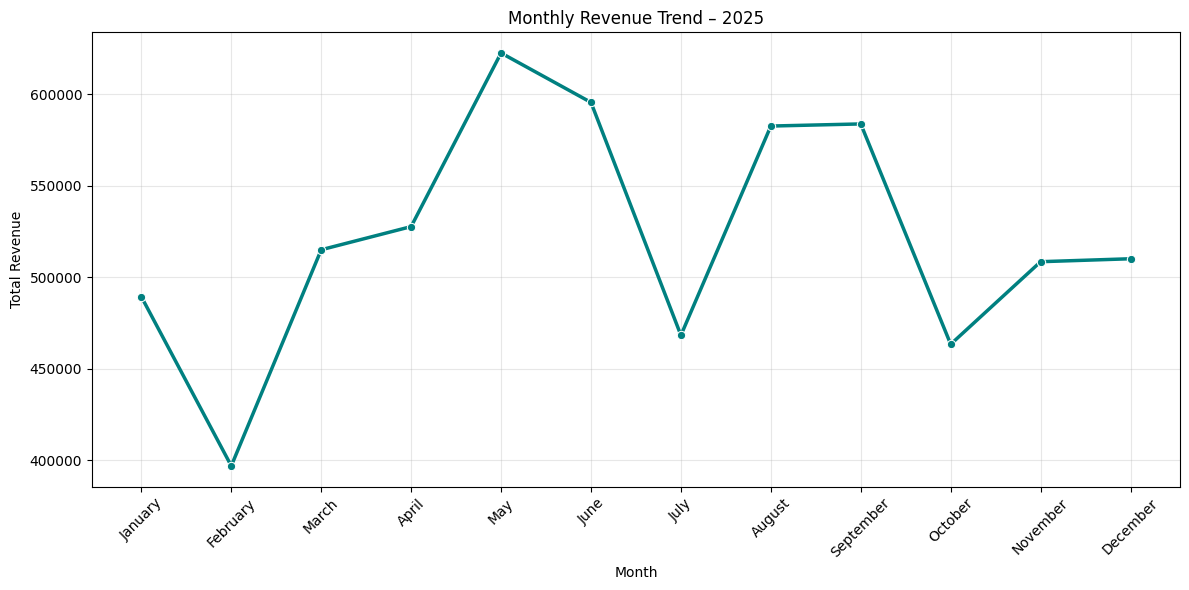

In [6]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_sales,
    x='month_name',
    y='total_revenue',
    marker='o',
    color='teal',
    linewidth=2.5
)

plt.title('Monthly Revenue Trend – 2025')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('monthly_revenue_trend.png',
            dpi=150, bbox_inches='tight')
plt.show()

In [7]:
best_month = monthly_sales.loc[
    monthly_sales['total_revenue'].idxmax()
]

worst_month = monthly_sales.loc[
    monthly_sales['total_revenue'].idxmin()
]

print("Highest Revenue Month:")
print(best_month[['month_name', 'total_revenue']])

print("\nLowest Revenue Month:")
print(worst_month[['month_name', 'total_revenue']])

Highest Revenue Month:
month_name                 May
total_revenue    622477.892531
Name: 4, dtype: object

Lowest Revenue Month:
month_name            February
total_revenue    396928.098826
Name: 1, dtype: object


key takeaway: May generated the highest revenue, while February generated the lowest revenue during 2025. The business should investigate what contributed to May's stronger performance.

In [8]:
# Analyse category performance
category_sales = df.groupby('category').agg(
    total_revenue=('revenue', 'sum'),
    total_orders=('order_id', 'count'),
    average_revenue=('revenue', 'mean'),
    total_quantity=('quantity', 'sum')
).reset_index()

# Sort by revenue
category_sales = category_sales.sort_values(
    by='total_revenue', ascending=False
)

display(category_sales.round(2))

,category,total_revenue,total_orders,average_revenue,total_quantity
1,Electronics,2399899.92,314,7642.99,948
3,Home & Kitchen,1346075.11,305,4413.36,931
4,Sports,1077808.10,301,3580.76,877
2,Fashion,841762.03,285,2953.55,832
0,Beauty,597797.61,295,2026.43,874


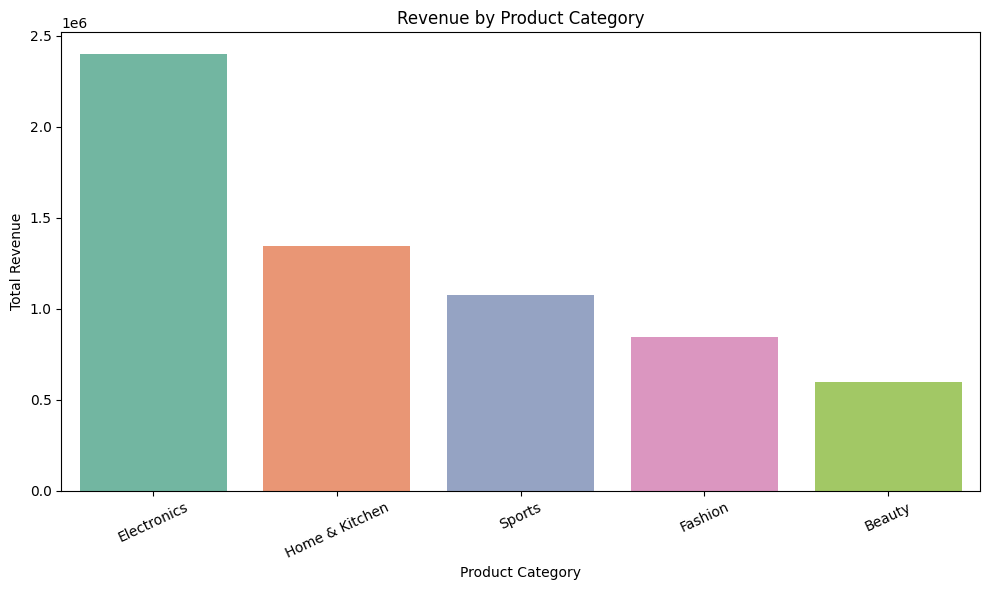

In [9]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_sales,
    x='category',
    y='total_revenue',
    hue='category',
    palette='Set2',
    legend=False
)

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=25)

plt.tight_layout()
plt.savefig('category_revenue.png', dpi=150,
            bbox_inches='tight')
plt.show()

In [10]:
# Create monthly category pivot table
monthly_category = pd.pivot_table(
    df,
    values='revenue',
    index='month_name',
    columns='category',
    aggfunc='sum',
    fill_value=0
)

# Arrange months in calendar order
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_category = monthly_category.reindex(month_order)

display(monthly_category.round(2))

category,Beauty,Electronics,Fashion,Home & Kitchen,Sports
month_name,,,,,
January,47589.03,222129.69,60577.74,69691.79,89341.95
February,43674.95,118632.74,55578.67,103780.74,75261.00
March,40240.38,196157.45,76656.50,138402.49,63535.09
April,51487.87,191063.29,72910.57,116027.04,96151.88
May,74464.27,216051.02,86620.33,107620.37,137721.90
June,44041.66,271529.22,62987.80,125699.22,91227.57
July,29680.88,169203.51,56017.38,122757.47,90614.96
August,35505.59,281019.18,93647.63,110105.76,62287.95
September,56932.95,221823.71,64602.41,124588.11,115775.73


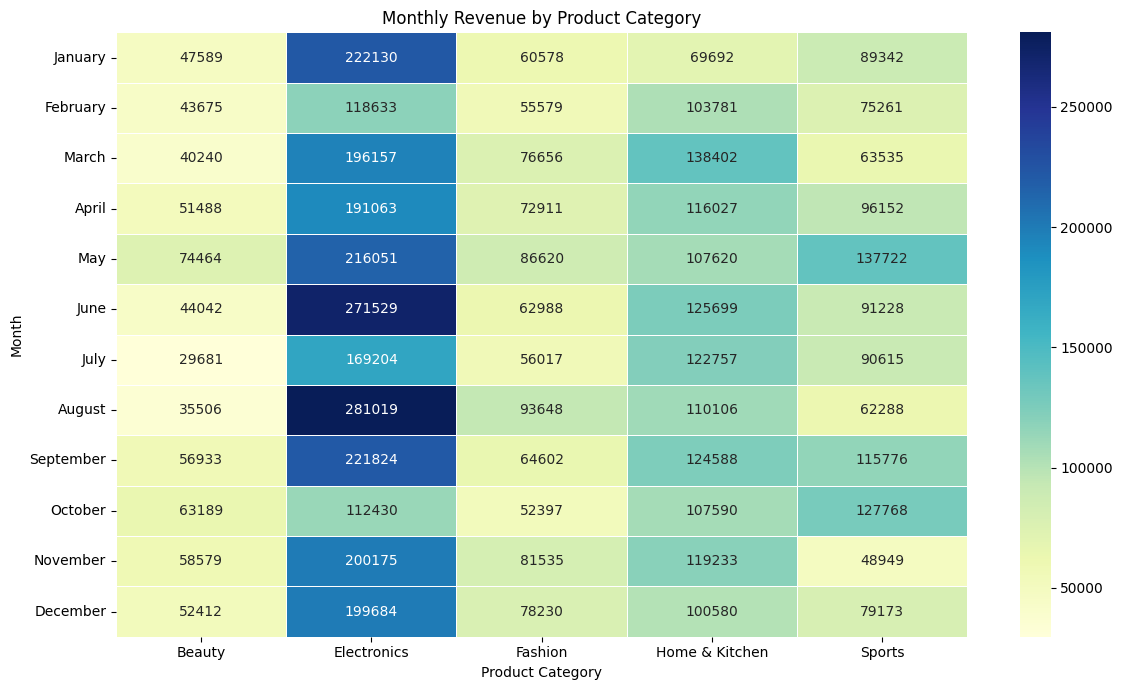

In [11]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    monthly_category,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu',
    linewidths=0.5
)

plt.title('Monthly Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Month')

plt.tight_layout()
plt.savefig('monthly_category_heatmap.png',
            dpi=150, bbox_inches='tight')
plt.show()

In [12]:
# Calculate total spending per customer
customer_sales = df.groupby('customer_id').agg(
    total_spending=('revenue', 'sum'),
    total_orders=('order_id', 'count')
).reset_index()

# Sort customers by spending
customer_sales = customer_sales.sort_values(
    by='total_spending',
    ascending=False
)

# Display top 10 customers
print("Top 10 Valuable Customers:")
display(customer_sales.head(10).round(2))

Top 10 Valuable Customers:


,customer_id,total_spending,total_orders
0,CUST_001,1370468.38,338
1,CUST_002,601849.12,139
2,CUST_003,381504.59,97
3,CUST_004,250626.80,63
4,CUST_005,193815.03,48
5,CUST_006,171253.09,32
6,CUST_007,154055.48,42
7,CUST_008,151716.85,32
14,CUST_015,112707.67,24
9,CUST_010,110796.79,23


In [13]:
# Calculate top 10% of customers
total_customers = len(customer_sales)

top_10_count = int(np.ceil(total_customers * 0.10))

top_customers = customer_sales.head(top_10_count)

# Calculate revenue contribution
total_revenue = customer_sales['total_spending'].sum()

top_10_revenue = top_customers['total_spending'].sum()

revenue_share = (top_10_revenue / total_revenue) * 100

print("Total Unique Customers:", total_customers)
print("Top 10% Customer Count:", top_10_count)

print("Total Business Revenue:", round(total_revenue, 2))
print("Revenue from Top 10% Customers:", round(top_10_revenue, 2))
print("Top 10% Revenue Contribution:", round(revenue_share, 2), "%")

Total Unique Customers: 168
Top 10% Customer Count: 17
Total Business Revenue: 6263342.78
Revenue from Top 10% Customers: 4069984.1
Top 10% Revenue Contribution: 64.98 %


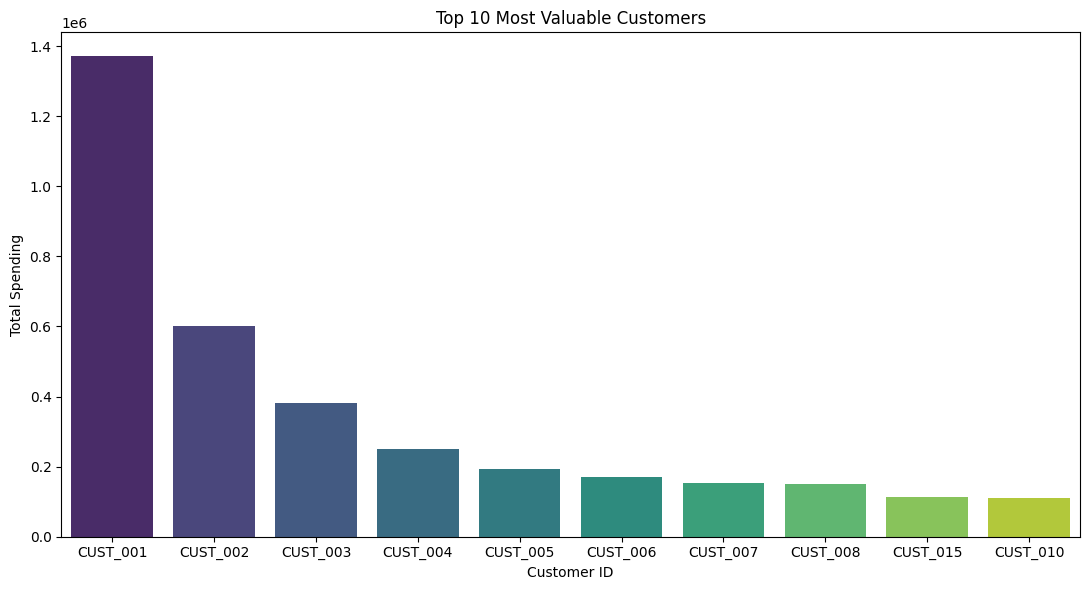

In [15]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=customer_sales.head(10),
    x='customer_id',
    y='total_spending',
    hue='customer_id',
    palette='viridis',
    legend=False
)

plt.title('Top 10 Most Valuable Customers')
plt.xlabel('Customer ID')
plt.ylabel('Total Spending')

plt.tight_layout()
plt.savefig('top_10_customers.png', dpi=150,
            bbox_inches='tight')
plt.show()

key takeaway: The top 10% of customers contribute 64.98% of total revenue, highlighting the importance of customer retention and loyalty programmes.

## Business Recommendations

Based on the sales analysis, the following recommendations are suggested:

**1. Improve Customer Retention**

The top 10% of customers contribute 64.98% of total revenue. The company should introduce loyalty programmes, exclusive offers and rewards to retain these valuable customers.

**2. Focus on Product Categories**

Electronics generates the highest revenue of 2,399,899.92. The company should maintain sufficient stock and promote popular electronics products. Marketing strategies should also be improved for the lower-performing Beauty category.

**3. Improve Monthly Sales Performance**

May recorded the highest revenue, while February recorded the lowest. The company should investigate the reasons behind these differences and plan suitable promotional campaigns to improve sales during weaker months.

**Conclusion:** Customer retention, category-based marketing and monthly sales monitoring can help the business make better decisions.